## Setup

Keep [`example_data.py`](example_data.py) and [`data_fidelity_metrics.py`](data_fidelity_metrics.py) beside this notebook. The project environment already supplies NumPy, pandas, and Matplotlib.

In [1]:
#| label: setup
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

from data_fidelity_metrics import (
    empirical_feature_hellinger_details,
    empirical_feature_hellinger_distance,
)
from example_data import (
    METRIC_CATEGORICAL_COLUMNS,
    METRIC_NUMERIC_COLUMNS,
    make_example_views,
)

## Learning goals

You will learn how to align empirical supports, calculate a Hellinger distance for each column, and average those distances into one data-fidelity metric.

## 1. Metric and inputs

| Property | Value |
|---|---|
| Metric | Average empirical Hellinger distance |
| Family | Data fidelity |
| Origin | Established; implemented in `ifcfill-experiments` |
| Classifier | None |
| Input | $\widetilde X,\widetilde Y$ |
| Holdout | None |
| Range | $[0,1]$; smaller is better |

Unlike the previous metric, this one compares each column's distribution separately. It does not measure relationships between columns.

## 2. Hellinger distance for one column

For column $j$, let $p_{jb}$ and $q_{jb}$ be the aligned empirical probabilities of bin or category $b$ in $\widetilde X$ and $\widetilde Y$. Then

$$
H_j(X,Y)=\sqrt{\frac12\sum_{b=1}^{B_j}
\left(\sqrt{p_{jb}}-\sqrt{q_{jb}}\right)^2}.
$$

The supports must match before subtraction:

- categorical columns use the exact union of labels observed in both tables;
- numerical columns use ten equal-width bins spanning the pooled minimum and maximum.

A label or bin absent from one table receives probability zero in that table.

## 3. Average across columns

If the complete representations contain $q$ columns, the reported metric is

$$
D_{\mathrm{Hell}}(X,Y)=\frac1q\sum_{j=1}^{q}H_j(X,Y).
$$

Every transformed column receives equal weight, regardless of its datatype or number of categories.

In [2]:
#| label: calculate-hellinger

example = make_example_views()
X_tilde, Y_tilde = example.X_tilde, example.Y_tilde

details = empirical_feature_hellinger_details(
    X_tilde,
    Y_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)
D_hell = empirical_feature_hellinger_distance(
    X_tilde,
    Y_tilde,
    categorical_columns=METRIC_CATEGORICAL_COLUMNS,
    numeric_columns=METRIC_NUMERIC_COLUMNS,
)

display(details.round(4))
print(f"Average empirical Hellinger distance = {D_hell:.6f}")
assert abs(D_hell - details["distance"].mean()) < 1e-12

,column,type,distance
0,region__code,categorical,0.3442
1,age__missing,categorical,0.0305
2,income_k__missing,categorical,0.0305
3,outcome,categorical,0.0712
4,age,numerical,0.6137
5,income_k,numerical,0.2952


Average empirical Hellinger distance = 0.230866


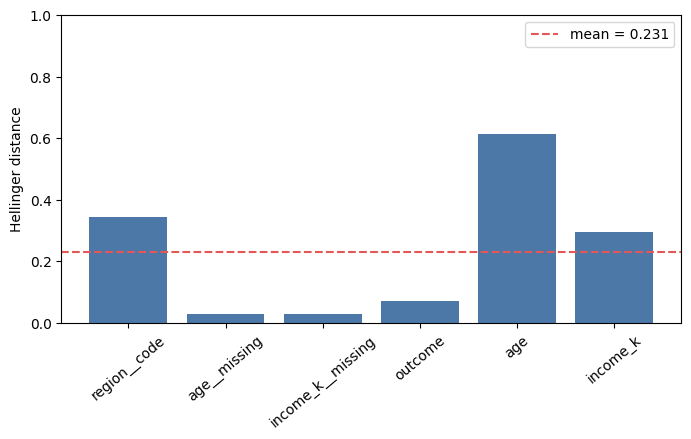

In [3]:
#| label: fig-feature-hellinger
#| fig-cap: "Per-column Hellinger distances whose arithmetic mean is the reported metric."

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(details["column"], details["distance"], color="#4c78a8")
ax.axhline(D_hell, color="#e45756", linestyle="--", label=f"mean = {D_hell:.3f}")
ax.set(ylabel="Hellinger distance", ylim=(0, 1))
ax.tick_params(axis="x", rotation=40)
ax.legend()
plt.show()

## 4. Interpretation

For the shared example, $D_{\mathrm{Hell}}(X,Y)\approx0.2309$. Zero would mean that every categorical frequency vector and every numerical ten-bin histogram matched exactly. A value of one would mean disjoint empirical support in every averaged component.

The metric is symmetric and permits different row counts. It can miss dependence differences because it examines columns one at a time; that is why it complements correlation-matrix difference rather than replacing it.

## Takeaway

Align the support, calculate one Hellinger distance per transformed column, and average. The implementation remains in [`data_fidelity_metrics.py`](data_fidelity_metrics.py); the notebook only supplies the mathematics and calls it.